# Importing libraries and dataset


In [ ]:
pip install statsmodels pmdarima


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 61.3 MB/s eta 0:00:00


In [ ]:
pip install numpy==1.23.5 pmdarima==2.0.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.1/17.1 MB 70.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 54.4 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
  Attempting uninstall: pmdarima
    Found existing installation: pmdarima 2.0.4
    Uninstalling pmdarima-2.0.4:
      Successfully uninstalled pmdarima-2.0.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.23.5 which is incompatible.
chex 0.1.89 requires numpy>=1.24.1, but you have numpy 1.23.5 which is incompatible.
xarray 2025.1.2 requires numpy>=1.24, but you have numpy 1.23.5 which is incompatible.
bigframes 1.42.0 requires numpy>=1.24.0, but you have numpy 1.23.5 which is incompatible.
albument

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pmdarima import auto_arima
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.stattools import adfuller
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA

In [ ]:
df = pd.read_csv('Walmart.csv')
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


Checking number of unique rows in each feature

In [ ]:
df.nunique().sort_values()

,0
Holiday_Flag,2
Store,45
Date,143
Unemployment,349
Fuel_Price,892
CPI,2145
Temperature,3528
Weekly_Sales,6435


Checking if any feature has null values

In [ ]:
print(df.isnull().any())

Store           False
Date            False
Weekly_Sales    False
Holiday_Flag    False
Temperature     False
Fuel_Price      False
CPI             False
Unemployment    False
dtype: bool


Checking if there are any duplicate rows

In [ ]:
duplicates = df.duplicated()
print("Number of duplicate rows:", duplicates.sum())

Number of duplicate rows: 0


# Pre Processing


Date column -> Weekday, Month, Year

In [ ]:
df.Date=pd.to_datetime(df.Date, format='%d-%m-%Y')

df['Weekday'] = df.Date.dt.weekday
df['Month'] = df.Date.dt.month
df['Year'] = df.Date.dt.year

df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Weekday,Month,Year
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,4,2,2010
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,4,2,2010
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,4,2,2010
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,4,2,2010
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,4,3,2010


In [ ]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'
df['Season'] = df.Month.apply(get_season)
df.sample(5)

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Weekday,Month,Year,Season
3798,27,2011-08-19,1781905.24,0,72.97,3.942,140.128920,7.850,4,8,2011,Summer
2909,21,2011-01-14,650789.13,0,34.14,2.983,211.117671,8.028,4,1,2011,Winter
659,5,2011-10-07,309111.47,0,71.64,3.285,217.612365,6.300,4,10,2011,Autumn
3290,24,2010-02-12,1414107.10,1,25.94,2.940,131.586613,8.326,4,2,2010,Winter
704,5,2012-08-17,314014.18,0,87.52,3.571,222.627675,5.603,4,8,2012,Summer


In [ ]:
numeric_cols = ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

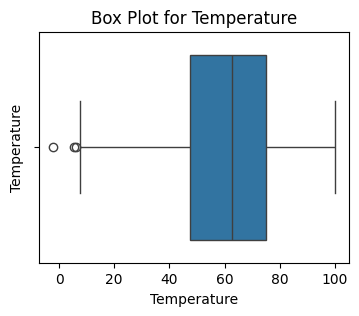

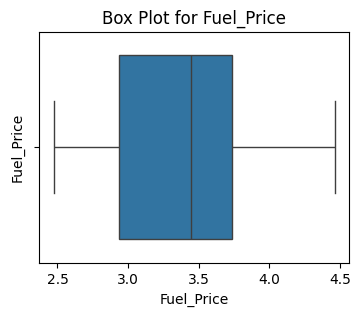

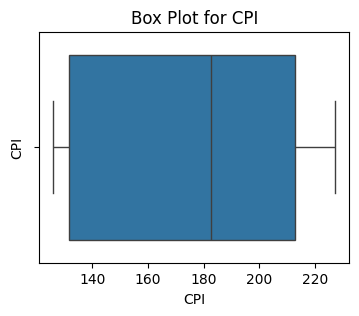

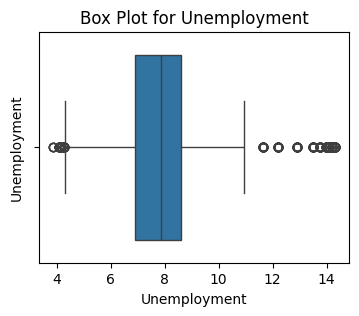

In [ ]:
for col in numeric_cols:
    plt.figure(figsize=(4, 3))
    sns.boxplot(data=df, x=col)
    plt.title(f'Box Plot for {col}')
    plt.ylabel(col)
    plt.show()

In [ ]:
numeric_cols = ['Temperature', 'Unemployment']
df_no_outliers = df.copy()
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"Outliers for {col}:")
    print(outliers)
    df_no_outliers = df_no_outliers[(df_no_outliers[col] >= lower_bound) & (df_no_outliers[col] <= upper_bound)]
df_no_outliers


Outliers for Temperature:
      Store       Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
910       7 2011-02-04     558027.77             0        -2.06       3.011   
2336     17 2011-01-07    1083071.14             0         6.23       2.891   
3626     26 2011-01-28     817485.14             0         5.54       3.243   

             CPI  Unemployment  Weekday  Month  Year  Season  
910   191.762589         8.818        4      2  2011  Winter  
2336  127.191774         6.866        4      1  2011  Winter  
3626  133.105968         7.907        4      1  2011  Winter  
Outliers for Unemployment:
      Store       Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
555       4 2012-07-06    2224499.28             0        80.37       3.187   
556       4 2012-07-13    2100252.61             0        76.86       3.224   
557       4 2012-07-20    2175563.69             0        79.14       3.263   
558       4 2012-07-27    2048613.65             0        81.0

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Weekday,Month,Year,Season
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,4,2,2010,Winter
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,4,2,2010,Winter
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,4,2,2010,Winter
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,4,2,2010,Winter
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,4,3,2010,Spring
...,...,...,...,...,...,...,...,...,...,...,...,...
6430,45,2012-09-28,713173.95,0,64.88,3.997,192.013558,8.684,4,9,2012,Autumn
6431,45,2012-10-05,733455.07,0,64.89,3.985,192.170412,8.667,4,10,2012,Autumn
6432,45,2012-10-12,734464.36,0,54.47,4.000,192.327265,8.667,4,10,2012,Autumn
6433,45,2012-10-19,718125.53,0,56.47,3.969,192.330854,8.667,4,10,2012,Autumn


In [ ]:
df_no_outliers.sample(5)

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Weekday,Month,Year,Season
112,1,2012-03-30,1649604.63,0,67.61,3.845,221.361012,7.348,4,3,2012,Spring
2967,21,2012-02-24,747099.07,0,54.81,3.555,220.275944,7.057,4,2,2012,Winter
2978,21,2012-05-11,649945.54,0,74.14,3.688,221.363221,6.891,4,5,2012,Spring
5180,37,2010-09-17,501251.40,0,82.10,2.582,210.292450,8.360,4,9,2010,Autumn
1765,13,2011-01-14,1682316.31,0,20.60,2.903,127.300935,7.470,4,1,2011,Winter


**PCA**

In [ ]:
numerical_features = ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment']
X = df[numerical_features]

# Standardize the data (PCA is sensitive to scale)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA(n_components=2)  # Reduce to 2 principal components
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame with the transformed features
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])

# Concatenate with non-numerical features if needed
final_df = pd.concat([df[['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag']], pca_df], axis=1)

print("Explained Variance Ratio:", pca.explained_variance_ratio_)

Explained Variance Ratio: [0.33365397 0.28720875]


In [ ]:
final_df

,Store,Date,Weekly_Sales,Holiday_Flag,PC1,PC2
0,1,2010-02-05,1643690.90,0,1.092458,-1.596603
1,1,2010-02-12,1641957.44,1,1.091952,-1.790889
2,1,2010-02-19,1611968.17,0,1.119835,-1.771110
3,1,2010-02-26,1409727.59,0,1.123303,-1.421490
4,1,2010-03-05,1554806.68,0,1.084853,-1.347668
...,...,...,...,...,...,...
6430,45,2012-09-28,713173.95,0,-0.203891,1.087071
6431,45,2012-10-05,733455.07,0,-0.188165,1.072741
6432,45,2012-10-12,734464.36,0,-0.242615,0.639106
6433,45,2012-10-19,718125.53,0,-0.214652,0.687624


In [ ]:
df.to_csv('Walmart_preprocessed.csv', index=False)

# EDA

<ipython-input-67-cb3f1501dd2a>:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Holiday_Flag', y='Weekly_Sales', data=df, palette="tab10")


<Axes: xlabel='Holiday_Flag', ylabel='Weekly_Sales'>

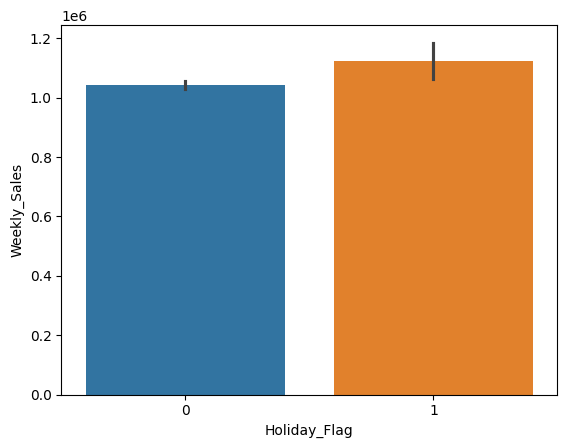

In [ ]:
sns.barplot(x='Holiday_Flag', y='Weekly_Sales', data=df, palette="tab10")

In [ ]:
df_holiday = df.loc[df['Holiday_Flag']==True]
df_holiday['Date'].unique()

<DatetimeArray>
['2010-02-12 00:00:00', '2010-09-10 00:00:00', '2010-11-26 00:00:00',
 '2010-12-31 00:00:00', '2011-02-11 00:00:00', '2011-09-09 00:00:00',
 '2011-11-25 00:00:00', '2011-12-30 00:00:00', '2012-02-10 00:00:00',
 '2012-09-07 00:00:00']
Length: 10, dtype: datetime64[ns]

Thanksgiving: 26-Nov-10, 25-Nov-11, 23-Nov-12, 29-Nov-13

In [ ]:
df_no_outliers.loc[(df['Date'] == '2010-11-26')|(df['Date'] == '2011-11-25'),'Thanksgiving'] = True
df_no_outliers.loc[(df['Date'] != '2010-11-26')&(df['Date'] != '2011-11-25'),'Thanksgiving'] = False
df_no_outliers.sample(3)

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Weekday,Month,Year,Season,Thanksgiving
1939,14,2011-08-19,1896873.99,0,72.98,3.747,186.509307,8.625,4,8,2011,Summer,False
4538,32,2012-02-10,1129422.86,1,23.34,3.103,196.919506,8.256,4,2,2012,Winter,False
5,1,2010-03-12,1439541.59,0,57.79,2.667,211.380643,8.106,4,3,2010,Spring,False


<Axes: xlabel='Thanksgiving', ylabel='Weekly_Sales'>

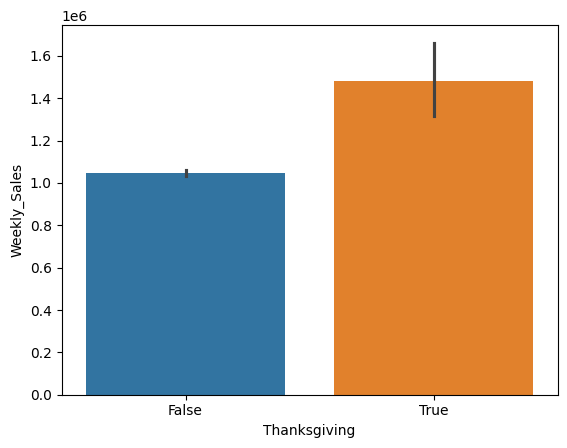

In [ ]:
sns.barplot(x='Thanksgiving', y='Weekly_Sales', data=df_no_outliers, palette="tab10", hue='Thanksgiving', legend=False)

From the above graph, it is seen that Black friday sales affect the weekly_sales


**Fuel Price, CPI , Unemployment , Temperature Effects**

<Axes: xlabel='Fuel_Price'>

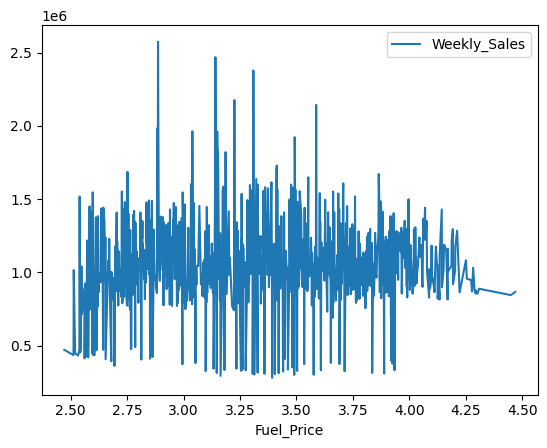

In [ ]:
fuel_price = pd.pivot_table(df, values = "Weekly_Sales", index= "Fuel_Price")
fuel_price.plot()

<Axes: xlabel='Temperature'>

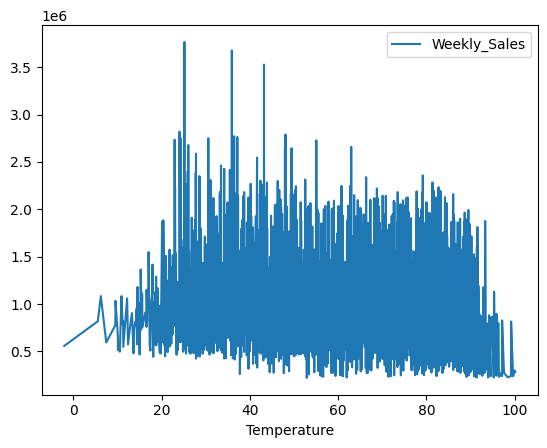

In [ ]:
temp = pd.pivot_table(df, values = "Weekly_Sales", index= "Temperature")
temp.plot()

<Axes: xlabel='CPI'>

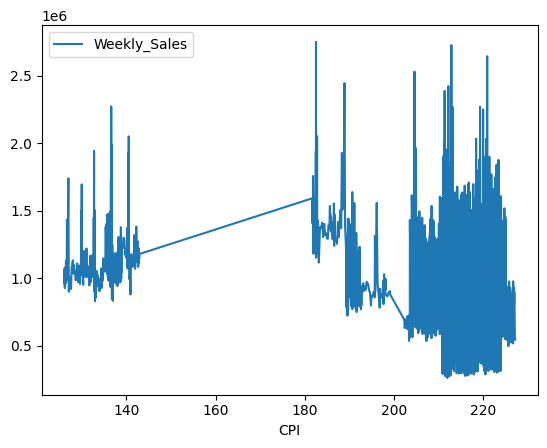

In [ ]:
CPI = pd.pivot_table(df, values = "Weekly_Sales", index= "CPI")
CPI.plot()

<Axes: xlabel='Unemployment'>

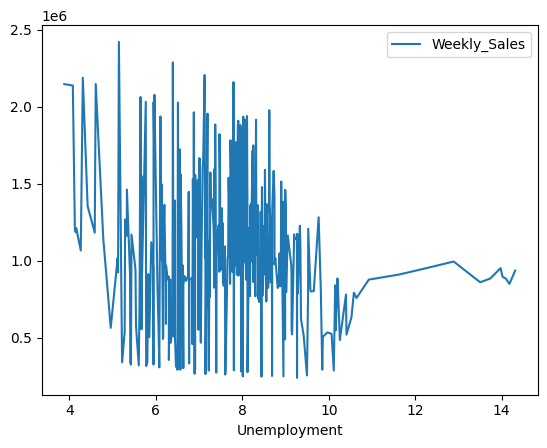

In [ ]:
unemployment = pd.pivot_table(df, values = "Weekly_Sales", index= "Unemployment")
unemployment.plot()

From graphs, it is seen that there are no significant patterns between CPI, temperature, unemployment rate, fuel price vs weekly sales.
There is no data for CPI between 140-180.

<ipython-input-40-d867e1b06835>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Month', y='Weekly_Sales', data=grouped_data, palette='magma')


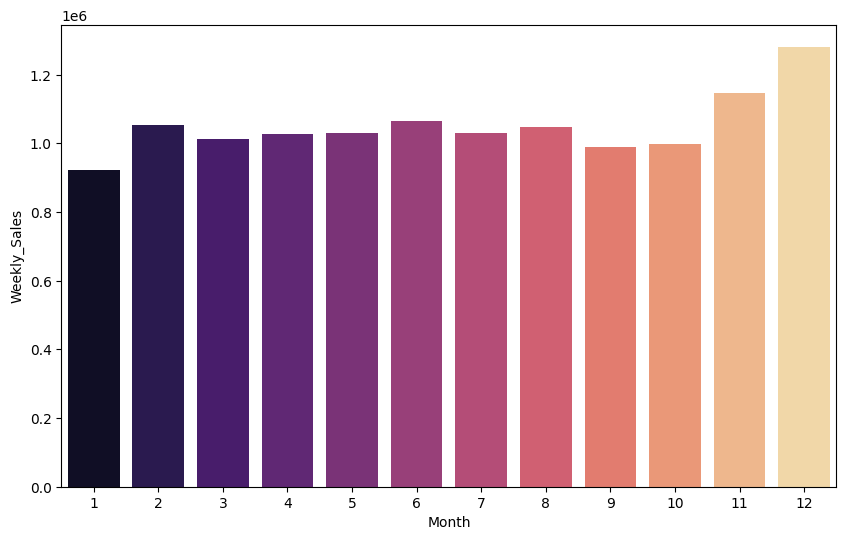

In [ ]:
grouped_data = df.groupby(['Month'])['Weekly_Sales'].mean().reset_index()

plt.figure(figsize=(10,6))
sns.barplot(x='Month', y='Weekly_Sales', data=grouped_data, palette='magma')
plt.show()

<ipython-input-41-624529711fdb>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Season', y='Weekly_Sales', data=grouped_data, palette='magma')


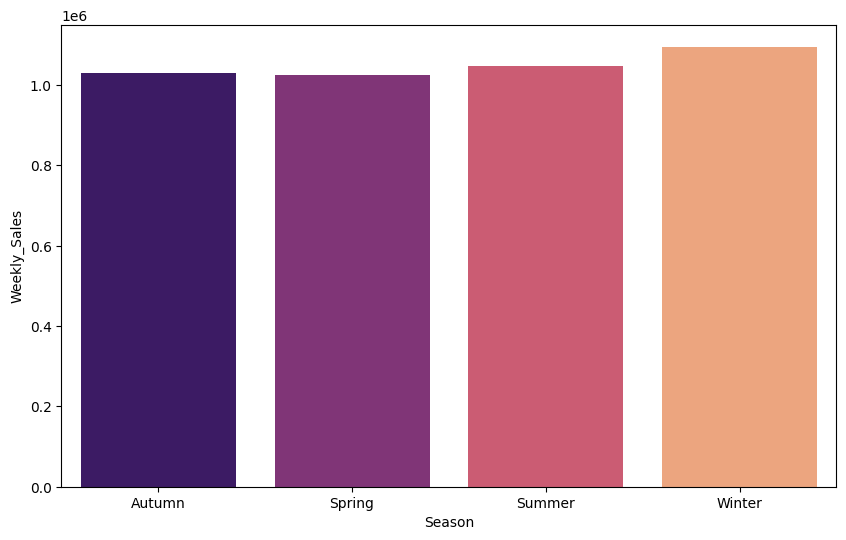

In [ ]:
grouped_data = df.groupby(['Season'])['Weekly_Sales'].mean().reset_index()

plt.figure(figsize=(10,6))
sns.barplot(x='Season', y='Weekly_Sales', data=grouped_data, palette='magma')
plt.show()

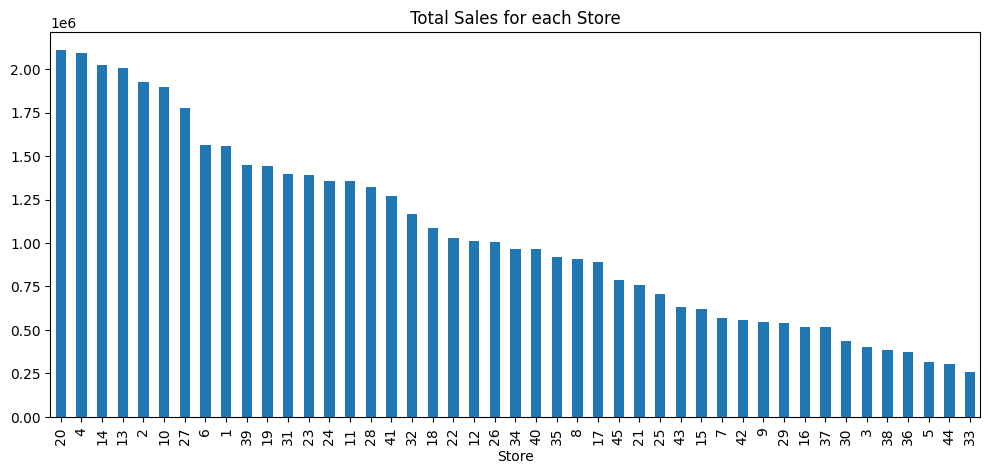

In [ ]:
plt.figure(figsize=(12,5))
df.groupby('Store')['Weekly_Sales'].mean().sort_values(ascending=False).plot(kind='bar');
plt.title('Total Sales for each Store');

Stores 20 ,4 ,14 ,13 ,2 achieved the highest sales with sales over 2M while stores like 33,44,5 achieve the lowest sales with sales around 0.25M

<Axes: xlabel='Date'>

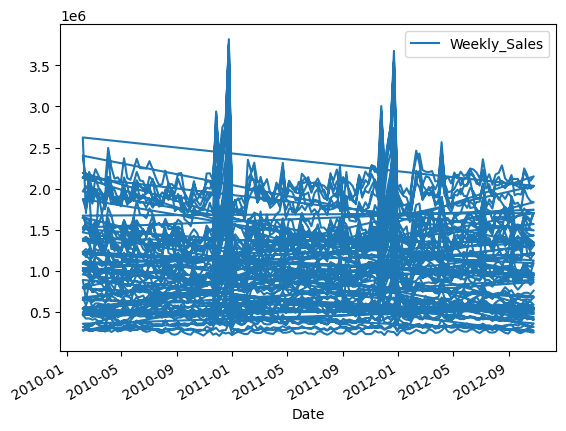

In [ ]:
df.plot(kind='line',x="Date",y="Weekly_Sales")

# Time Series Analysis


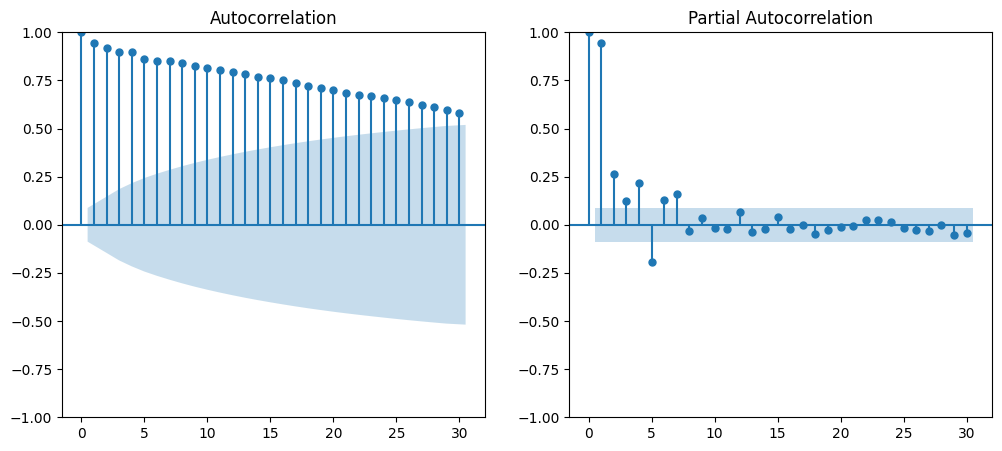

In [ ]:
sales_sample = df_no_outliers["Weekly_Sales"].iloc[:500]

# Plot ACF and PACF
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
plot_acf(sales_sample, ax=ax[0], lags=30)
plot_pacf(sales_sample, ax=ax[1], lags=30)
plt.show()

In [ ]:
# Aggregate weekly sales across all stores
weekly_sales = df_no_outliers.groupby("Date")["Weekly_Sales"].sum()
print(weekly_sales.sample(5))

Date
2012-06-15    43210954.19
2011-06-10    44951060.86
2012-08-10    42765865.16
2012-04-20    40298750.48
2010-06-18    45062524.12
Name: Weekly_Sales, dtype: float64


In [ ]:
# Split data into training (80%) and testing (20%)
train_size = int(len(weekly_sales) * 0.8)
train, test = weekly_sales[:train_size], weekly_sales[train_size:]


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


In [ ]:
train_diff = train.diff().dropna()
print(train_diff)
print(train)


Date
2010-02-12   -1302214.79
2010-02-19      45402.88
2010-02-26   -4319475.89
2010-03-05    2770218.79
2010-03-12    -542875.44
                 ...    
2012-03-09     446772.34
2012-03-16     -89582.85
2012-03-23   -1709933.60
2012-03-30     308152.00
2012-04-06    7082654.06
Name: Weekly_Sales, Length: 113, dtype: float64
Date
2010-02-05    46619845.70
2010-02-12    45317630.91
2010-02-19    45363033.79
2010-02-26    41043557.90
2010-03-05    43813776.69
                 ...     
2012-03-09    41986730.18
2012-03-16    41897147.33
2012-03-23    40187213.73
2012-03-30    40495365.73
2012-04-06    47578019.79
Name: Weekly_Sales, Length: 114, dtype: float64


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters 

Mean Absolute Error (MAE): 2498102.3231376503
Root Mean Squared Error (RMSE): 2833625.526593462
Mean Absolute Percentage Error (MAPE): 6.055040503641757


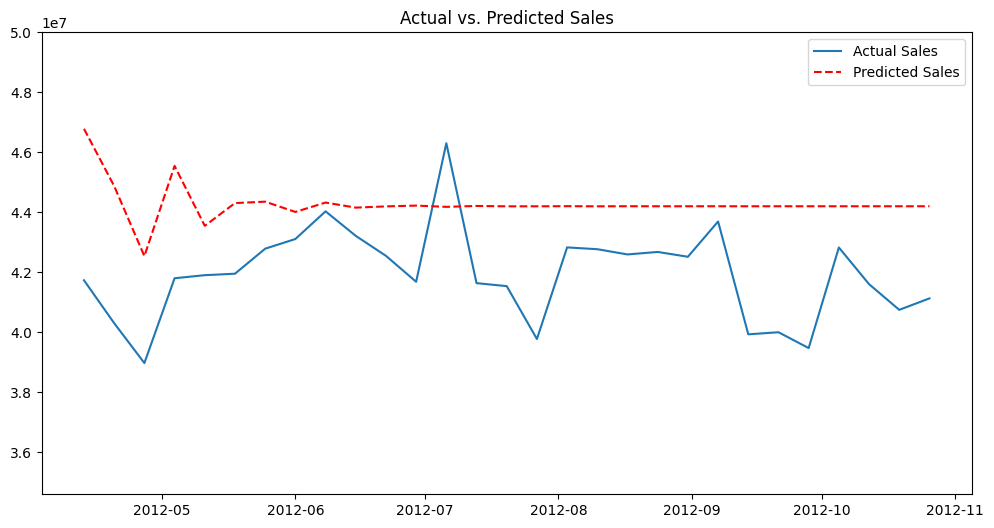

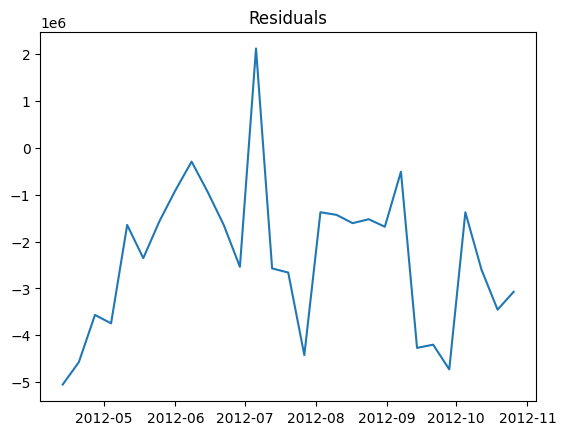

In [ ]:
arima_train_model = ARIMA(train, order=(2,0,2))
arima_train_result = arima_train_model.fit()

test_predictions = arima_train_result.forecast(steps=len(test))

mae = mean_absolute_error(test, test_predictions)
rmse = np.sqrt(mean_squared_error(test, test_predictions))
mape = np.mean(np.abs((test - test_predictions) / test)) * 100

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")

plt.figure(figsize=(12, 6))
plt.plot(test.index, test, label="Actual Sales")
plt.plot(test.index, test_predictions, label="Predicted Sales", linestyle="dashed", color="red")
plt.ylim(min(weekly_sales)-1000000, 50000000)
plt.legend()
plt.title("Actual vs. Predicted Sales")
plt.show()


In [ ]:

def check_stationarity(series):
    result = adfuller(series)
    print("ADF Statistic:", result[0])
    print("p-value:", result[1])
    if result[1] <= 0.05:
        print("✅ Data is stationary")
    else:
        print("❌ Data is not stationary, differencing needed")

check_stationarity(weekly_sales)



ADF Statistic: -5.748010518479755
p-value: 6.057747684119082e-07
✅ Data is stationary


In [ ]:
# Split data into training (80%) and testing (20%)
train_size1 = int(len(weekly_sales) * 0.8)
train1, test1 = weekly_sales[:train_size1], weekly_sales[train_size1:]

# Apply differencing if needed (set d=1 if not stationary)
d = 0

p, q = 2, 2
P, Q = 1, 0
D = 0
S = 52

sarima_model = sm.tsa.statespace.SARIMAX(train,
                                         order=(p, d, q),
                                         seasonal_order=(P, D, Q, S),
                                         enforce_stationarity=False,
                                         enforce_invertibility=False)
sarima_fit = sarima_model.fit()

print(sarima_fit.summary())

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


                                      SARIMAX Results                                      
Dep. Variable:                        Weekly_Sales   No. Observations:                  114
Model:             SARIMAX(2, 0, 2)x(1, 0, [], 52)   Log Likelihood                -991.374
Date:                             Tue, 22 Apr 2025   AIC                           1994.748
Time:                                     16:12:53   BIC                           2007.314
Sample:                                 02-05-2010   HQIC                          1999.663
                                      - 04-06-2012                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6451      8.592      0.075      0.940     -16.195      17.485
ar.L2          0.3431      

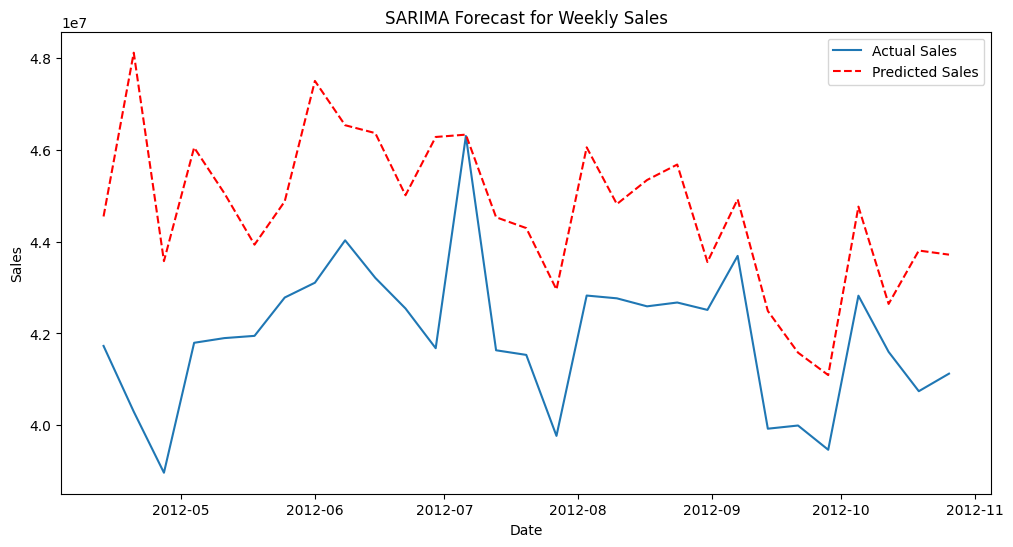

Mean Absolute Error (MAE): 2773439.442366339
Root Mean Squared Error (RMSE): 3118087.7655597045
Mean Absolute Percentage Error (MAPE): 6.670122451903443


In [ ]:

test_predictions1 = sarima_fit.forecast(steps=len(test))

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(test1.index, test1, label="Actual Sales")
plt.plot(test1.index, test_predictions1, label="Predicted Sales", linestyle="dashed", color="red")
plt.title("SARIMA Forecast for Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.show()

mae = mean_absolute_error(test1, test_predictions1)
rmse = np.sqrt(mean_squared_error(test1, test_predictions1))
mape = np.mean(np.abs((test - test_predictions1) / test1)) * 100

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[52] intercept   : AIC=3823.409, Time=15.05 sec
 ARIMA(0,0,0)(0,0,0)[52] intercept   : AIC=3879.393, Time=0.05 sec


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(1,0,0)(1,0,0)[52] intercept   : AIC=3844.859, Time=4.13 sec


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(0,0,1)(0,0,1)[52] intercept   : AIC=3843.454, Time=0.65 sec
 ARIMA(0,0,0)(0,0,0)[52]             : AIC=4341.240, Time=0.02 sec


... (25 outputs left out)

 ARIMA(3,0,3)(1,0,0)[52] intercept   : AIC=3830.237, Time=12.84 sec


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(2,0,2)(1,0,0)[52]             : AIC=3847.561, Time=5.31 sec

Best model:  ARIMA(2,0,2)(1,0,0)[52] intercept
Total fit time: 204.529 seconds
                                      SARIMAX Results                                      
Dep. Variable:                                   y   No. Observations:                  114
Model:             SARIMAX(2, 0, 2)x(1, 0, [], 52)   Log Likelihood               -1903.792
Date:                             Tue, 22 Apr 2025   AIC                           3821.584
Time:                                     16:09:34   BIC                           3840.738
Sample:                                 02-05-2010   HQIC                          3829.358
                                      - 04-06-2012                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


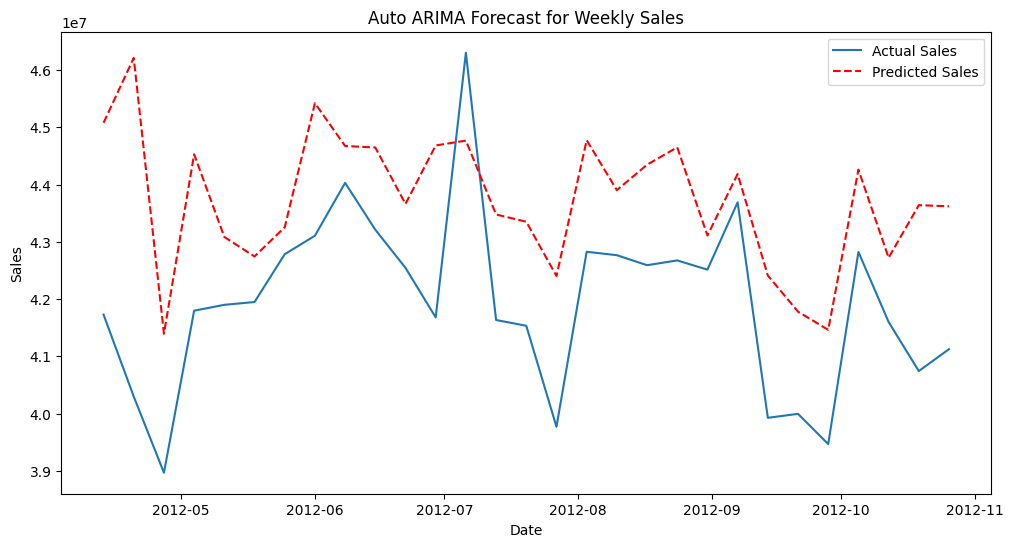

Mean Absolute Error (MAE): 1907314.9745563513
Root Mean Squared Error (RMSE): 2194916.126286085
Mean Absolute Percentage Error (MAPE): 4.6004400001841095


In [ ]:
train_size1 = int(len(weekly_sales) * 0.8)
train1, test1 = weekly_sales[:train_size1], weekly_sales[train_size1:]

# Auto ARIMA: Automatically selects the best parameters (p, d, q, P, D, Q, S)
# seasonal=True indicates that the model should consider seasonality
model = auto_arima(train1, seasonal=True, m=52, stepwise=True, trace=True,
                      suppress_warnings=True, seasonal_test='ocsb')

# Summary of the model
print(model.summary())

# Forecast using the trained model
test_predictions1 = model.predict(n_periods=len(test1))
# Plot results
plt.figure(figsize=(12, 6))
plt.plot(test1.index, test1, label="Actual Sales")
plt.plot(test1.index, test_predictions1, label="Predicted Sales", linestyle="dashed", color="red")
plt.title("Auto ARIMA Forecast for Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.show()

# Calculate performance metrics
mae = mean_absolute_error(test1, test_predictions1)
rmse = np.sqrt(mean_squared_error(test1, test_predictions1))
mape = np.mean(np.abs((test1 - test_predictions1) / test1)) * 100

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")

**With Outliers**

In [ ]:
# Aggregate weekly sales across all stores
weekly_sales_ot = df.groupby("Date")["Weekly_Sales"].sum()
print(weekly_sales_ot.sample(5))

Date
2012-06-01    48281649.72
2011-12-16    60085695.94
2011-04-01    43458991.19
2011-11-18    46438980.56
2010-09-03    47194257.61
Name: Weekly_Sales, dtype: float64


In [ ]:
# Split data into training (80%) and testing (20%)
train_size_ot = int(len(weekly_sales_ot) * 0.8)
train_ot, test_ot = weekly_sales_ot[:train_size_ot], weekly_sales[train_size_ot:]

arima_train_model_ot = ARIMA(train_ot, order=(2,0,2))
arima_train_result_ot = arima_train_model_ot.fit()

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters 

Mean Absolute Error (MAE): 5402880.407195551
Root Mean Squared Error (RMSE): 5657315.32365564
Mean Absolute Percentage Error (MAPE): 13.021879653836649


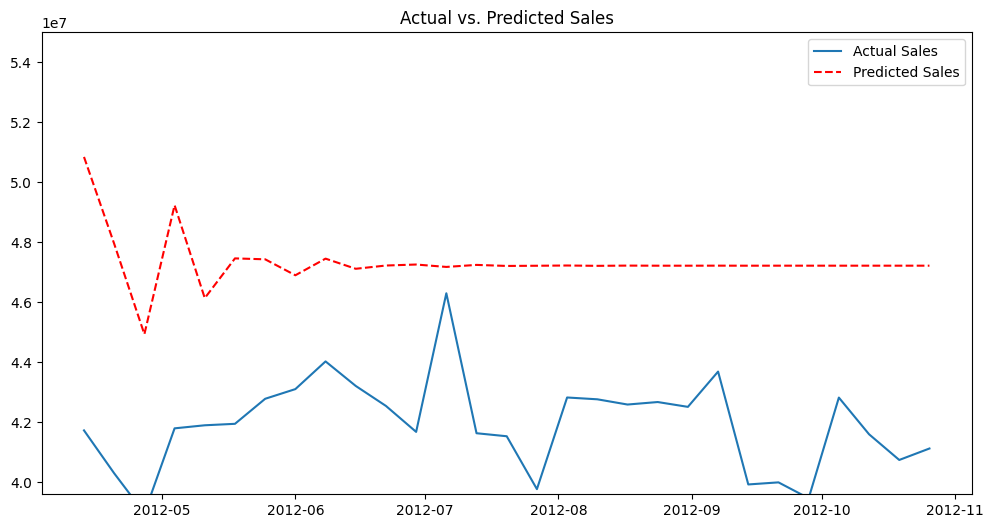

In [ ]:
# Predict on test data
test_predictions_ot = arima_train_result_ot.forecast(steps=len(test))

# Evaluate performance
mae = mean_absolute_error(test_ot, test_predictions_ot)
rmse = np.sqrt(mean_squared_error(test_ot, test_predictions_ot))
mape = np.mean(np.abs((test_ot - test_predictions_ot) / test_ot)) * 100

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")

# Plot actual vs. predicted sales
plt.figure(figsize=(12, 6))
plt.plot(test_ot.index, test_ot, label="Actual Sales")
plt.plot(test_ot.index, test_predictions_ot, label="Predicted Sales", linestyle="dashed", color="red")
plt.ylim(min(weekly_sales_ot), 55000000)
plt.legend()
plt.title("Actual vs. Predicted Sales")
plt.show()

# Machine Learning Models


In [ ]:
df

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Weekday,Month,Year,Season
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,4,2,2010,Winter
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,4,2,2010,Winter
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,4,2,2010,Winter
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,4,2,2010,Winter
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,4,3,2010,Spring
...,...,...,...,...,...,...,...,...,...,...,...,...
6430,45,2012-09-28,713173.95,0,64.88,3.997,192.013558,8.684,4,9,2012,Autumn
6431,45,2012-10-05,733455.07,0,64.89,3.985,192.170412,8.667,4,10,2012,Autumn
6432,45,2012-10-12,734464.36,0,54.47,4.000,192.327265,8.667,4,10,2012,Autumn
6433,45,2012-10-19,718125.53,0,56.47,3.969,192.330854,8.667,4,10,2012,Autumn


In [ ]:
X = df_no_outliers[['Store', 'Temperature', 'Fuel_Price', 'Holiday_Flag', 'Unemployment', 'CPI', 'Month', 'Weekday', 'Thanksgiving']]
y = df_no_outliers['Weekly_Sales']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
std = StandardScaler()

print('\033[1mStandardardization on Training set'.center(120))
Train_X_std = std.fit_transform(X_train)
Train_X_std = pd.DataFrame(Train_X_std, columns=X.columns)
display(Train_X_std.describe())

print('\n','\033[1mStandardardization on Testing set'.center(120))
Test_X_std = std.transform(X_test)
Test_X_std = pd.DataFrame(Test_X_std, columns=X.columns)
display(Test_X_std.describe())

                                         Standardardization on Training set                                         


,Store,Temperature,Fuel_Price,Holiday_Flag,Unemployment,CPI,Month,Weekday,Thanksgiving
count,4.760000e+03,4.760000e+03,4.760000e+03,4.760000e+03,4.760000e+03,4.760000e+03,4.760000e+03,4760.0,4.760000e+03
mean,-1.791284e-17,-7.366656e-16,-1.865921e-16,1.194189e-17,-3.194457e-16,-2.955619e-16,1.015061e-16,0.0,-2.537653e-17
std,1.000105e+00,1.000105e+00,1.000105e+00,1.000105e+00,1.000105e+00,1.000105e+00,1.000105e+00,0.0,1.000105e+00
min,-1.676982e+00,-2.877139e+00,-1.892514e+00,-2.724878e-01,-2.729431e+00,-1.245505e+00,-1.704772e+00,0.0,-1.129865e-01
25%,-9.085905e-01,-7.349992e-01,-9.712449e-01,-2.724878e-01,-6.627064e-01,-1.073402e+00,-7.702201e-01,0.0,-1.129865e-01
50%,-6.336000e-02,1.187560e-01,1.689076e-01,-2.724878e-01,1.062143e-01,3.888367e-01,1.643319e-01,0.0,-1.129865e-01
75%,8.587096e-01,7.685237e-01,8.299130e-01,-2.724878e-01,6.198950e-01,9.971674e-01,7.873666e-01,0.0,-1.129865e-01
max,1.703940e+00,2.164341e+00,2.454658e+00,3.669889e+00,2.565801e+00,1.353549e+00,1.721919e+00,0.0,8.850612e+00



                                          Standardardization on Testing set                                          


,Store,Temperature,Fuel_Price,Holiday_Flag,Unemployment,CPI,Month,Weekday,Thanksgiving
count,1191.000000,1191.000000,1191.000000,1191.000000,1191.000000,1191.000000,1191.000000,1191.0,1191.000000
mean,-0.030908,-0.009125,-0.015291,0.022115,0.004994,0.051112,0.004258,0.0,0.067640
std,1.028053,1.008416,0.981052,1.037086,0.971266,1.013059,1.039776,0.0,1.260068
min,-1.676982,-2.734075,-1.801041,-0.272488,-2.729431,-1.245505,-1.704772,0.0,-0.112987
25%,-0.985430,-0.752406,-0.990846,-0.272488,-0.662706,-1.073270,-0.770220,0.0,-0.112987
50%,-0.063360,0.108693,0.143861,-0.272488,0.106214,0.429594,0.164332,0.0,-0.112987
75%,0.858710,0.821288,0.777642,-0.272488,0.605493,1.024947,0.787367,0.0,-0.112987
max,1.703940,1.989728,2.454658,3.669889,2.565801,1.354025,1.721919,0.0,8.850612


Linear Regression MAE: 443837.576925467
Linear Regression RMSE: 543963.0414245258
Linear Regression R²: 0.15460758482809223


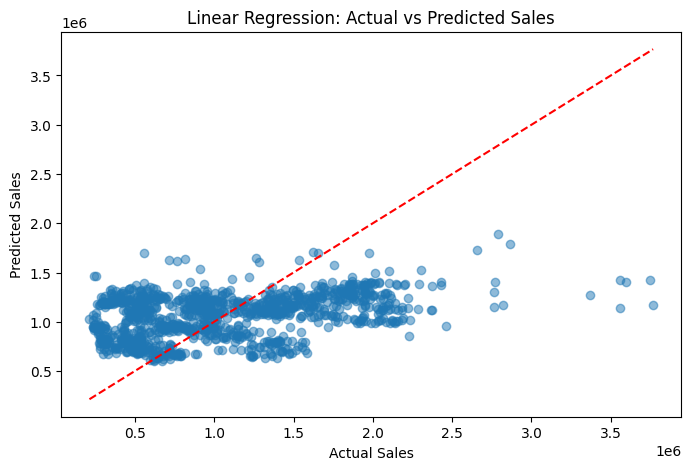

(1191, 9)
         Store  Temperature  Fuel_Price  Holiday_Flag  Unemployment       CPI  \
0     0.628192     0.535162    1.021572     -0.272488      0.169424  1.046827   
1     0.705031     0.936065    0.498866     -0.272488      0.122217  0.602354   
2    -0.601234    -1.474793    1.398356     -0.272488      0.179026 -0.953613   
3     1.012388     1.325001    0.215733     -0.272488      0.366255  1.014639   
4    -0.985430    -0.251413    0.829913      3.669889     -0.139424 -1.134479   
...        ...          ...         ...           ...           ...       ...   
1186 -1.215947    -2.075332   -0.675045     -0.272488      0.429465  0.573927   
1187  1.012388     0.088022   -1.385054     -0.272488      0.605493  0.930931   
1188 -0.447556    -1.069538    0.718838     -0.272488     -1.053168 -1.121330   
1189 -1.676982     0.383940   -1.221708     -0.272488      0.071009  0.921237   
1190 -1.139108     0.814761    0.646966     -0.272488     -1.854894  1.319228   

         Month  W

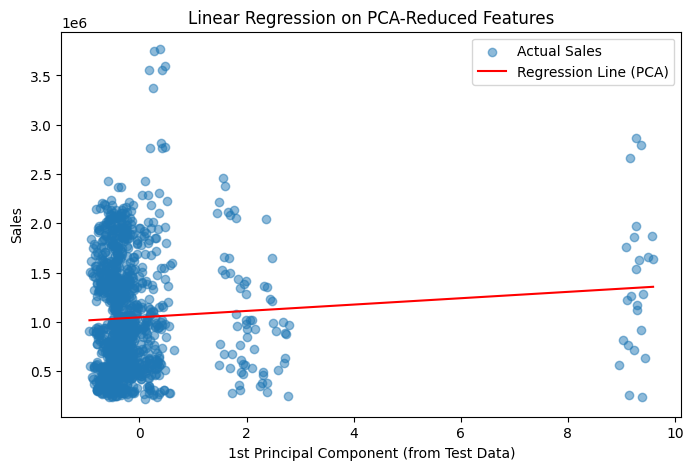

In [ ]:
# Initialize and train the model
lr_model = LinearRegression()
lr_model.fit(Train_X_std, y_train)

# Make predictions
y_pred_lr = lr_model.predict(Test_X_std)

# Evaluate the model
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print(f"Linear Regression MAE: {mae_lr}")
print(f"Linear Regression RMSE: {rmse_lr}")
print(f"Linear Regression R²: {r2_lr}")

# Plot actual vs predicted values
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_lr, alpha=0.5)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], linestyle="--", color="red")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Linear Regression: Actual vs Predicted Sales")
plt.show()



print(Test_X_std.shape)
print(Test_X_std)

if Test_X_std.shape[1] == 1:
    # Sort test input for a clean line
    sorted_idx = np.argsort(Test_X_std[:, 0])
    X_sorted = Test_X_std[sorted_idx]
    y_sorted_pred = y_pred_lr[sorted_idx]

    # Plot actual test points and regression line
    plt.figure(figsize=(8, 5))
    plt.scatter(Test_X_std, y_test, alpha=0.5, label="Actual Sales")
    plt.plot(X_sorted, y_sorted_pred, color="red", label="Regression Line")
    plt.xlabel("Standardized Feature")
    plt.ylabel("Sales")
    plt.title("Linear Regression: Regression Line on Test Data")
    plt.legend()
    plt.show()
else:
    print("Regression line plot only works with one input feature.")


# Apply PCA to reduce to 1 component
pca = PCA(n_components=1)
X_test_pca = pca.fit_transform(Test_X_std)

# Fit linear regression on PCA-reduced test data
lr_pca = LinearRegression()
lr_pca.fit(X_test_pca, y_test)
y_pred_pca = lr_pca.predict(X_test_pca)

r2_pca = r2_score(y_test, y_pred_pca)
mse_pca = mean_squared_error(y_test, y_pred_pca)

print(f"PCA Regression R²: {r2_pca:.4f}")
print(f"PCA Regression MSE: {mse_pca:.4f}")

# Sort for smooth plot
sorted_idx = np.argsort(X_test_pca[:, 0])
X_sorted = X_test_pca[sorted_idx]
y_sorted = y_test.iloc[sorted_idx]
y_pred_sorted = y_pred_pca[sorted_idx]

# Plot
plt.figure(figsize=(8, 5))
plt.scatter(X_sorted, y_sorted, alpha=0.5, label="Actual Sales")
plt.plot(X_sorted, y_pred_sorted, color="red", label="Regression Line (PCA)")
plt.xlabel("1st Principal Component (from Test Data)")
plt.ylabel("Sales")
plt.title(f"Linear Regression on PCA-Reduced Features")
plt.legend()
plt.show()

In [ ]:
lin_reg = make_pipeline(
        PolynomialFeatures(degree=2),
        LinearRegression()
)
param_grid = {'polynomialfeatures__degree':[2,3,4,5]}

grid_search = GridSearchCV(estimator= lin_reg,param_grid= param_grid,cv=5,scoring='r2')
grid_search.fit(Train_X_std,y_train)
best_params = grid_search.best_params_
best_estimator = grid_search.best_estimator_
best_score = grid_search.best_score_
print("Best parameters are: ",best_params)

Best parameters are:  {'polynomialfeatures__degree': 3}


Mean Squared Error (MSE): 209870222694.17206
R-squared Score (R²): 0.40038790624642184


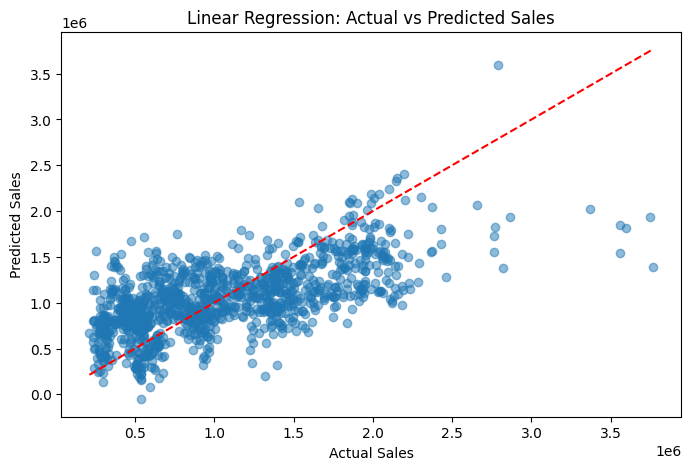

Polynomial Regression (degree=3) MSE: 209870222694.1721
Polynomial Regression (degree=3) R²: 0.4004


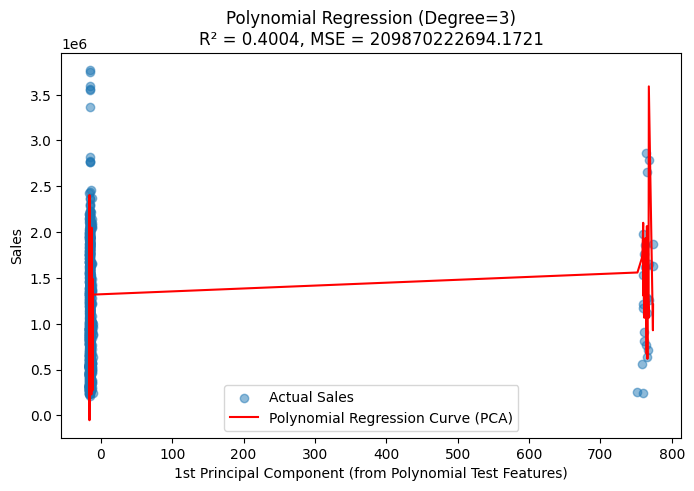

In [ ]:
poly = PolynomialFeatures(degree=3)
X_train_poly = poly.fit_transform(Train_X_std)
X_test_poly = poly.transform(Test_X_std)

# Train a Linear Regression model
model = LinearRegression()
model.fit(X_train_poly, y_train)

# Make predictions
y_pred = model.predict(X_test_poly)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse}")
print(f"R-squared Score (R²): {r2}")

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], linestyle="--", color="red")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Linear Regression: Actual vs Predicted Sales")
plt.show()

# Transform input features to polynomial features (degree 3)
poly = PolynomialFeatures(degree=3)
X_train_poly = poly.fit_transform(Train_X_std)
X_test_poly = poly.transform(Test_X_std)

# Train Linear Regression on polynomial features
model = LinearRegression()
model.fit(X_train_poly, y_train)

# Predict on test set
y_pred = model.predict(X_test_poly)

# Evaluate performance
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Polynomial Regression (degree=3) MSE: {mse:.4f}")
print(f"Polynomial Regression (degree=3) R²: {r2:.4f}")

# ---- PCA Projection and Plot ----
# Reduce polynomial-transformed test features to 1D
pca = PCA(n_components=1)
X_test_pca = pca.fit_transform(X_test_poly)

# Sort for smooth line plotting
sorted_idx = np.argsort(X_test_pca[:, 0])
X_sorted = X_test_pca[sorted_idx]
y_sorted = y_test.iloc[sorted_idx]  # if y_test is a Series
y_pred_sorted = y_pred[sorted_idx]

# Plot the results
plt.figure(figsize=(8, 5))
plt.scatter(X_sorted, y_sorted, alpha=0.5, label="Actual Sales")
plt.plot(X_sorted, y_pred_sorted, color="red", label="Polynomial Regression Curve (PCA)")
plt.xlabel("1st Principal Component (from Polynomial Test Features)")
plt.ylabel("Sales")
plt.title(f"Polynomial Regression (Degree=3)\nR² = {r2:.4f}, MSE = {mse:.4f}")
plt.legend()
plt.show()

Random Forest - Mean Squared Error (MSE): 17751147051.10
Random Forest - R-squared Score (R²): 0.9493


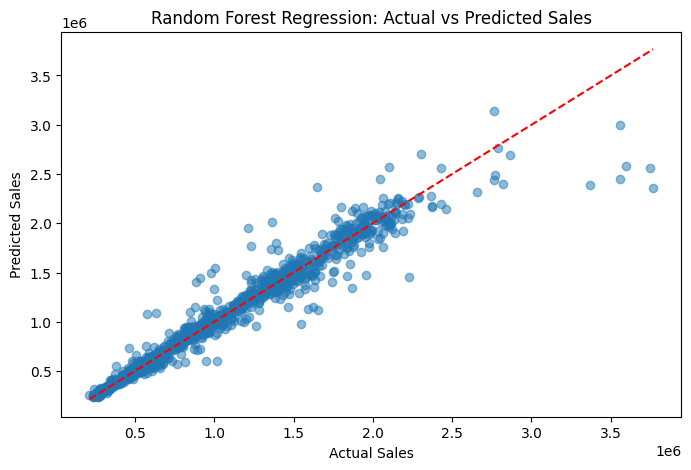


Polynomial Regression R²: 0.4004
Polynomial Regression MSE: 209870222694.17
Random Forest R²: 0.9493
Random Forest MSE: 17751147051.10


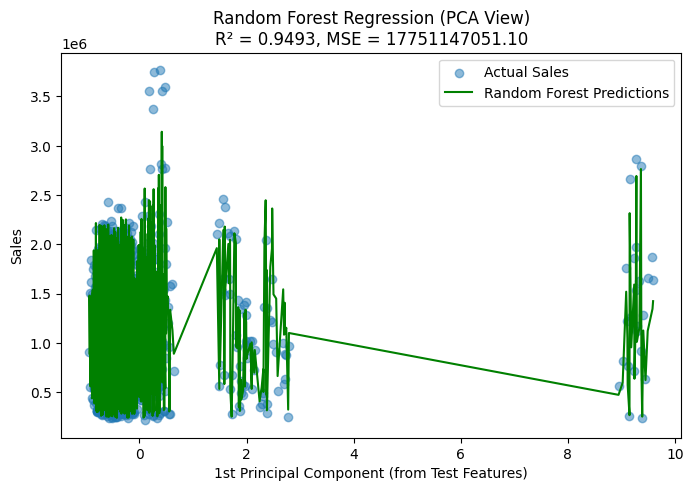

In [ ]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(Train_X_std, y_train)

# Make predictions
rf_y_pred = rf_model.predict(Test_X_std)

# Evaluate the Random Forest model
rf_mse = mean_squared_error(y_test, rf_y_pred)
rf_r2 = r2_score(y_test, rf_y_pred)

print(f"Random Forest - Mean Squared Error (MSE): {rf_mse:.2f}")
print(f"Random Forest - R-squared Score (R²): {rf_r2:.4f}")

# Plot Actual vs Predicted Sales for Random Forest
plt.figure(figsize=(8, 5))
plt.scatter(y_test, rf_y_pred, alpha=0.5)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], linestyle="--", color="red")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Random Forest Regression: Actual vs Predicted Sales")
plt.show()

# Compare R² and MSE of Polynomial Regression vs Random Forest
print(f"\nPolynomial Regression R²: {r2:.4f}")
print(f"Polynomial Regression MSE: {mse:.2f}")
print(f"Random Forest R²: {rf_r2:.4f}")
print(f"Random Forest MSE: {rf_mse:.2f}")

# PCA transformation of test features for visualization
pca_rf = PCA(n_components=1)
X_test_pca_rf = pca_rf.fit_transform(Test_X_std)

# Sort for smooth plotting
sorted_idx_rf = np.argsort(X_test_pca_rf[:, 0])
X_sorted_rf = X_test_pca_rf[sorted_idx_rf]
y_sorted_rf = y_test.iloc[sorted_idx_rf]
y_pred_sorted_rf = rf_y_pred[sorted_idx_rf]

# Plot Random Forest on PCA projection
plt.figure(figsize=(8, 5))
plt.scatter(X_sorted_rf, y_sorted_rf, alpha=0.5, label="Actual Sales")
plt.plot(X_sorted_rf, y_pred_sorted_rf, color="green", label="Random Forest Predictions")
plt.xlabel("1st Principal Component (from Test Features)")
plt.ylabel("Sales")
plt.title(f"Random Forest Regression (PCA View)\nR² = {rf_r2:.4f}, MSE = {rf_mse:.2f}")
plt.legend()
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 500],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.3]
}

grid_search = GridSearchCV(XGBRegressor(), param_grid, cv=5)
grid_search.fit(Train_X_std, y_train)
print(grid_search.best_params_)

{'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 500}


XGBoost - Mean Squared Error (MSE): 14120948270.60
XGBoost - R-squared Score (R²): 0.9597


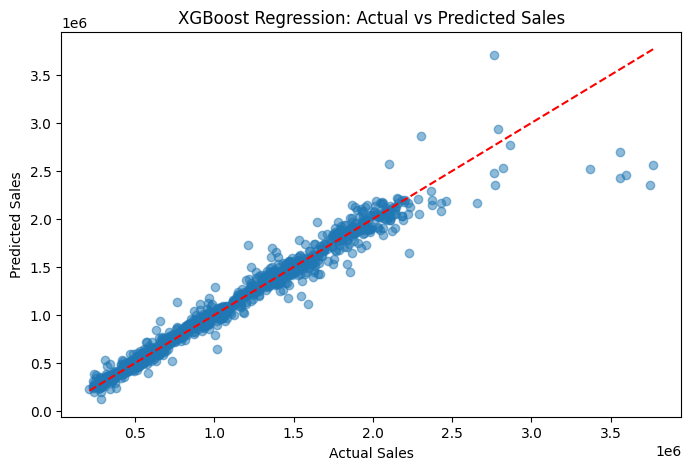


Polynomial Regression R²: 0.4004
Polynomial Regression MSE: 209870222694.17
Random Forest R²: 0.9493
Random Forest MSE: 17751147051.10
XGBoost R²: 0.9597
XGBoost MSE: 14120948270.60


In [ ]:
from xgboost import XGBRegressor, XGBClassifier

xgboost_reg_model = XGBRegressor(n_estimators=500, max_depth=7, learning_rate=0.1)
xgboost_reg_model.fit(Train_X_std, y_train)

# Make predictions
xg_y_pred = xgboost_reg_model.predict(Test_X_std)

# Evaluate the Random Forest model
xg_mse = mean_squared_error(y_test, xg_y_pred)
xg_r2 = r2_score(y_test, xg_y_pred)

print(f"XGBoost - Mean Squared Error (MSE): {xg_mse:.2f}")
print(f"XGBoost - R-squared Score (R²): {xg_r2:.4f}")

# Plot Actual vs Predicted Sales for Random Forest
plt.figure(figsize=(8, 5))
plt.scatter(y_test, xg_y_pred, alpha=0.5)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], linestyle="--", color="red")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("XGBoost Regression: Actual vs Predicted Sales")
plt.show()

# Compare R² and MSE of Polynomial Regression vs Random Forest
print(f"\nPolynomial Regression R²: {r2:.4f}")
print(f"Polynomial Regression MSE: {mse:.2f}")
print(f"Random Forest R²: {rf_r2:.4f}")
print(f"Random Forest MSE: {rf_mse:.2f}")
print(f"XGBoost R²: {xg_r2:.4f}")
print(f"XGBoost MSE: {xg_mse:.2f}")


[0]	validation_0-rmse:525597.61927	validation_1-rmse:549399.46693
[1]	validation_0-rmse:489112.98883	validation_1-rmse:512596.13648
[2]	validation_0-rmse:447671.28078	validation_1-rmse:471188.67502
[3]	validation_0-rmse:414218.50136	validation_1-rmse:438373.80861
[4]	validation_0-rmse:381173.99654	validation_1-rmse:404934.74089
[5]	validation_0-rmse:354241.22297	validation_1-rmse:378315.70239
[6]	validation_0-rmse:326760.21279	validation_1-rmse:350555.77943
[7]	validation_0-rmse:302388.90043	validation_1-rmse:326296.02159
[8]	validation_0-rmse:281011.79325	validation_1-rmse:304025.23960
[9]	validation_0-rmse:261954.05615	validation_1-rmse:284519.64844
[10]	validation_0-rmse:246212.76825	validation_1-rmse:268925.27097
[11]	validation_0-rmse:231221.99303	validation_1-rmse:253592.32677
[12]	validation_0-rmse:218815.45368	validation_1-rmse:241635.33466
[13]	validation_0-rmse:207088.73783	validation_1-rmse:230730.29404
[14]	validation_0-rmse:196084.14342	validation_1-rmse:221056.44748
[15]	

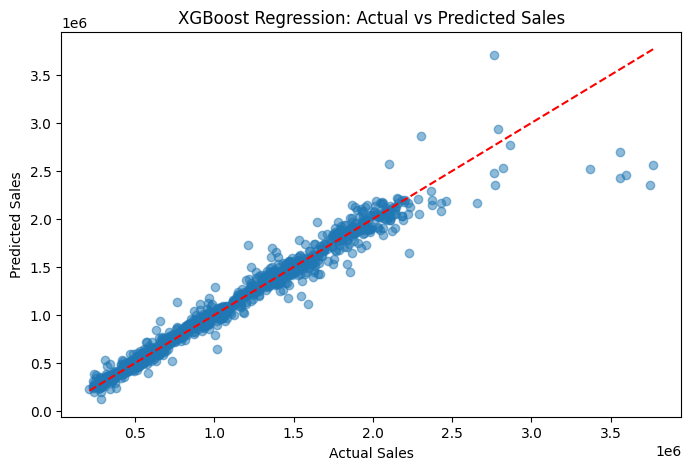


Polynomial Regression R²: 0.4004
Polynomial Regression MSE: 209870222694.17
Random Forest R²: 0.9493
Random Forest MSE: 17751147051.10
XGBoost R²: 0.9597
XGBoost MSE: 14120948270.60


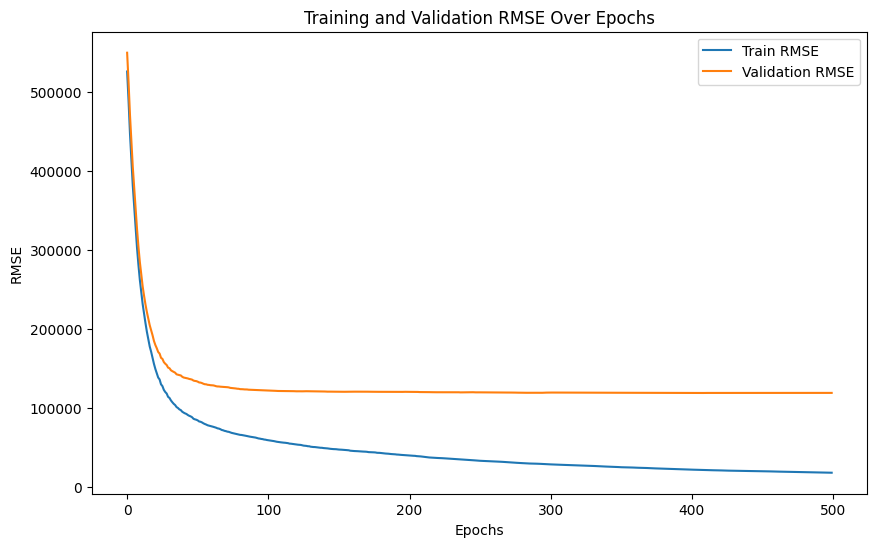

Training R²: 0.9990
Training MSE: 316603359.10
Test R²: 0.9597
Test MSE: 14120948270.60


In [ ]:
xgboost_reg_model = XGBRegressor(n_estimators=500, max_depth=7, learning_rate=0.1)

# Train the model with early stopping and eval set to monitor both training and validation sets
evals = [(Train_X_std, y_train), (Test_X_std, y_test)]
xgboost_reg_model.fit(
    Train_X_std, y_train,
    eval_set=evals,
    verbose=True
)
# Make predictions
xg_y_pred = xgboost_reg_model.predict(Test_X_std)

# Calculate metrics for the model (MSE and R²)
xg_mse = mean_squared_error(y_test, xg_y_pred)
xg_r2 = r2_score(y_test, xg_y_pred)

# Print out the metrics
print(f"XGBoost - Mean Squared Error (MSE): {xg_mse:.2f}")
print(f"XGBoost - R-squared Score (R²): {xg_r2:.4f}")

# Plot Actual vs Predicted Sales
plt.figure(figsize=(8, 5))
plt.scatter(y_test, xg_y_pred, alpha=0.5)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], linestyle="--", color="red")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("XGBoost Regression: Actual vs Predicted Sales")
plt.show()

# Compare R² and MSE of Polynomial Regression vs Random Forest vs XGBoost
print(f"\nPolynomial Regression R²: {r2:.4f}")
print(f"Polynomial Regression MSE: {mse:.2f}")
print(f"Random Forest R²: {rf_r2:.4f}")
print(f"Random Forest MSE: {rf_mse:.2f}")
print(f"XGBoost R²: {xg_r2:.4f}")
print(f"XGBoost MSE: {xg_mse:.2f}")

# Plot the training and validation loss curves
results = xgboost_reg_model.evals_result()
epochs = len(results['validation_0']['rmse'])
x_axis = range(0, epochs)

plt.figure(figsize=(10, 6))
plt.plot(x_axis, results['validation_0']['rmse'], label='Train RMSE')
plt.plot(x_axis, results['validation_1']['rmse'], label='Validation RMSE')
plt.xlabel('Epochs')
plt.ylabel('RMSE')
plt.title('Training and Validation RMSE Over Epochs')
plt.legend()
plt.show()

xg_train_pred = xgboost_reg_model.predict(Train_X_std)
train_r2 = r2_score(y_train, xg_train_pred)
train_mse = mean_squared_error(y_train, xg_train_pred)

print(f"Training R²: {train_r2:.4f}")
print(f"Training MSE: {train_mse:.2f}")

# Calculate R² and MSE for test set
xg_test_pred = xgboost_reg_model.predict(Test_X_std)
test_r2 = r2_score(y_test, xg_test_pred)
test_mse = mean_squared_error(y_test, xg_test_pred)

print(f"Test R²: {test_r2:.4f}")
print(f"Test MSE: {test_mse:.2f}")

XGBoost using PCA

XGBoost - Mean Squared Error (MSE): 361140960797.81
XGBoost - R-squared Score (R²): -0.1210


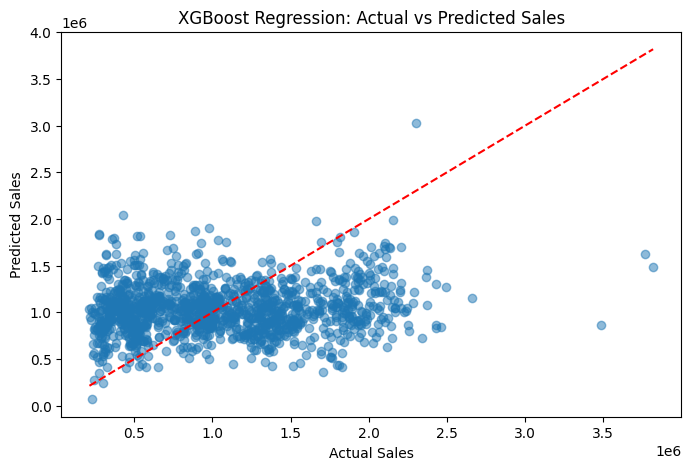

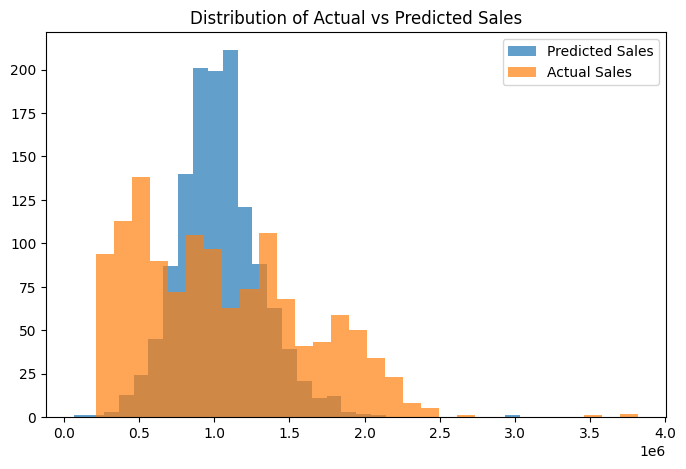

Train MSE: 162449275323.18, Train R²: 0.4884


In [ ]:
from xgboost import XGBRegressor, XGBClassifier

X = final_df[['PC1', 'PC2']]  # PCA-transformed features
y = final_df['Weekly_Sales']  # Target variable

# Split into train/test sets (80/20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

xgboost_reg_model = XGBRegressor()
xgboost_reg_model.fit(X_train, y_train)

# Make predictions
xg_y_pred = xgboost_reg_model.predict(X_test)

# Evaluate the Random Forest model
xg_mse = mean_squared_error(y_test, xg_y_pred)
xg_r2 = r2_score(y_test, xg_y_pred)

print(f"XGBoost - Mean Squared Error (MSE): {xg_mse:.2f}")
print(f"XGBoost - R-squared Score (R²): {xg_r2:.4f}")

# Plot Actual vs Predicted Sales for Random Forest
plt.figure(figsize=(8, 5))
plt.scatter(y_test, xg_y_pred, alpha=0.5)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], linestyle="--", color="red")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("XGBoost Regression: Actual vs Predicted Sales")
plt.show()


# Plot prediction distribution
plt.figure(figsize=(8, 5))
plt.hist(xg_y_pred, bins=30, alpha=0.7, label='Predicted Sales')
plt.hist(y_test, bins=30, alpha=0.7, label='Actual Sales')
plt.legend()
plt.title("Distribution of Actual vs Predicted Sales")
plt.show()

# Train performance
y_train_pred = xgboost_reg_model.predict(X_train)
train_mse = mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

print(f"Train MSE: {train_mse:.2f}, Train R²: {train_r2:.4f}")
